# BIOT 6900 · Module 7 · Assignment Starter (Neo4j)

### *Build a knowledge graph for YOUR Part I disease*

This is the starter for the graded assignment. The database plumbing, the Cypher
queries, and the graph algorithms are **already written and working** — your job
is to supply the **data for your own disease** (the cells marked **`# TODO`**) and
then **interpret** what the graph tells you.

It ships with a tiny placeholder example so it runs top to bottom as a skeleton.
Replace the example with your disease, section by section, re-running as you go.

**Before you start:** create a free Neo4j AuraDB instance and have your
`targets_ad.csv` from Module 2 ready. See the Module 7 lab guide for setup.
Run with **Kernel → Restart & Run All**.


## 0 · Install and connect

Run this, then paste your Neo4j connection details into the next cell. On AuraDB
Free the **username is your instance ID**, not `neo4j`.

In [1]:
# If the kernel restarts after installing, run the cells again from the top.
# %pip install neo4j networkx matplotlib pandas requests


In [2]:
from neo4j import GraphDatabase

# Load credentials from the git-ignored .env file (same pattern as the RealModel notebook).
import os, pathlib
for _d in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents, pathlib.Path.home() / "Documents/GitHub/biot6900"]:
    _f = _d / ".env"
    if _f.is_file():
        for _line in _f.read_text().splitlines():
            if "=" in _line and not _line.lstrip().startswith("#"):
                _k, _v = _line.split("=", 1)
                os.environ.setdefault(_k.strip(), _v.strip().strip("\"'"))
        break

NEO4J_URI      = os.environ["NEO4J_URI"]
NEO4J_USER     = os.environ["NEO4J_USERNAME"]   # the instance ID, not "neo4j"
NEO4J_PASSWORD = os.environ["NEO4J_PASSWORD"]

driver = GraphDatabase.driver(NEO4J_URI, auth=(NEO4J_USER, NEO4J_PASSWORD))

def run_query(cypher, **params):
    with driver.session() as session:
        return [r.data() for r in session.run(cypher, **params)]

try:
    driver.verify_connectivity(); print("Connected to Neo4j.")
except Exception as e:
    print("Not connected yet — check your .env. Details:", e)

run_query("MATCH (n) DETACH DELETE n")   # wipe the database before restarting

Connected to Neo4j.


[]

## 1 · Your data  (★ this is the part you edit)

Replace every value marked **`# TODO`** with your own disease. Read your genes
from `targets_ad.csv`, then fill in the phenotypes, pathways, drugs, variants, and
**at least one related disease that shares a phenotype** (that is what powers the
repurposing query in §4).

In [3]:
import pandas as pd
import networkx as nx

# ===========================================================================
# MY DISEASE: Alzheimer's disease, built from my own Part I results.
# [Name Year] tags match the reference list in my report.
#
# FROM MY EARLIER MODULES
#   Genes        : my Module 3 top-15 ranking (images/module3_assignment_final_ranking.csv)
#   gwas_p       : smallest P-VALUE among GWAS Catalog associations whose MAPPED_GENE includes the
#                  gene, in data/ad_gwas.tsv (Module 2; GWAS Catalog trait MONDO_0004975,
#                  https://www.ebi.ac.uk/gwas/efotraits/MONDO_0004975) [Sollis 2023]
#   rna_lfc      : rna_lfc column of targets_ad_v2.csv (Module 2), from GEO GSE104704
#                  (https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE104704) [Nativio 2018]
#   prot_lfc     : prot_lfc column of targets_ad_v2.csv (Module 2), from Synapse syn12269876,
#                  "Global quantitative analysis of the human brain proteome in Alzheimer's and
#                  Parkinson's Disease" (Sci Data 2018) [Ping 2018]
#   druggability : max(p_sm, p_ab), my Module 3 tractability model
#                  (images/module3_assignment_tractability_probabilities.csv); embeddings from
#                  ESM C 300M [EvolutionaryScale 2024] and ESM-2 [Lin 2023], labels from Open Targets [Buniello 2025]
#   Ensembl IDs  : primary-assembly gene IDs from MyGene.info (https://mygene.info/v3/query) [Xin 2016];
#                  for KCNQ2/KCNQ3/JAK1/CYP46A1 as returned by Open Targets (they agree)
#   Variants     : lead SNP per gene from data/ad_gwas.tsv (SNPS column of the min-p row);
#                  APOE rs429358 (e4) / rs7412 (e2) as in Module 3 anchor variants and Module 6
#   Patients     : Module 6 cohort: data/genotypes.csv, data/meta.csv, data/score.csv, data/variants.csv
#                  = 1000 Genomes phase 3 (release 20130502, GRCh37) genotypes [1000 Genomes Project Consortium 2015]
#                  scored with PGS Catalog PGS000334 [Zhang 2020; Lambert 2021]. See data/README.md.
#
# FROM PUBLIC DATABASES (no equivalent in my earlier data; all accessed 2026-10-30)
#   Phenotypes   : Human Phenotype Ontology annotations [Gargano 2024]
#                  https://purl.obolibrary.org/obo/hp/hpoa/phenotype.hpoa  (term names from
#                  https://purl.obolibrary.org/obo/hp.json). AD terms = union over OMIM:104300,
#                  ORPHA:1020 and the familial AD loci (OMIM:104310, 607822, 606889, 602096,
#                  609636, 615080, 608907). Disease IDs: OMIM [Amberger 2019], Orphanet [Orphanet n.d.].
#   Pathways     : Reactome ContentService (https://reactome.org/ContentService) [Milacic 2024]
#                  /data/mapping/UniProt/{accession}/pathways?species=9606, rolled up with
#                  /data/event/{stId}/ancestors so a gene counts toward its parent pathways too.
#   Drugs        : Open Targets Platform GraphQL API (https://api.platform.opentargets.org/api/v4/graphql)
#                  [Buniello 2025], target.drugAndClinicalCandidates for my genes and
#                  disease.drugAndClinicalCandidates for the related diseases (Open Targets disease IDs
#                  are Mondo IDs [Vasilevsky 2022]). Status = maxClinicalStage (PHASE_4 / APPROVAL ->
#                  "approved"). Drug IDs are ChEMBL IDs [Zdrazil 2024].
#   Related      : gene -> Mendelian disease from HPO genes_to_disease.txt
#                  (https://purl.obolibrary.org/obo/hp/hpoa/genes_to_disease.txt); shared phenotypes =
#                  HPO terms (or their HPO parent terms) annotated to both that disease and AD.
# ===========================================================================
DISEASE = "Alzheimer's disease"
DISEASE_ID = "MONDO:0004975; OMIM:104300"

# Citation strings stored as a `source` property on nodes and edges, so the evidence travels with the graph
SRC_GWAS    = "GWAS Catalog MONDO_0004975, data/ad_gwas.tsv (Module 2) [Sollis 2023]"
SRC_GENE    = ("gwas_p: GWAS Catalog [Sollis 2023]; rna_lfc: GSE104704 [Nativio 2018]; "
               "prot_lfc: syn12269876 [Ping 2018]; druggability: Module 3 tractability model "
               "[EvolutionaryScale 2024; Lin 2023; Buniello 2025]; ensembl: MyGene.info [Xin 2016]")
SRC_HPO     = "HPO phenotype.hpoa [Gargano 2024]"
SRC_REACT   = "Reactome ContentService, UniProt -> pathway incl. parent pathways [Milacic 2024]"
SRC_OT      = "Open Targets drugAndClinicalCandidates [Buniello 2025]; ChEMBL [Zdrazil 2024]"
SRC_PATIENT = ("1000 Genomes phase 3 genotypes [1000 Genomes Project Consortium 2015], data/genotypes.csv + data/meta.csv "
               "(Module 6); PRS = PGS000334 [Zhang 2020; Lambert 2021]; age and status SIMULATED")

GENES = [
    # symbol,    ensembl,           gwas_p, rna_lfc, prot_lfc, druggability
    ("HCN1",    "ENSG00000164588", 4e-13,  -0.82, -0.30, 0.879),   # Module 3 rank 1; Module 4 pocket 0.878
    ("SHANK2",  "ENSG00000162105", 1e-30,  -0.52, -0.24, 0.337),
    ("SLC30A3", "ENSG00000115194", 2e-11,  -1.67, -0.30, 0.414),
    ("SAMHD1",  "ENSG00000101347", 2e-36,   0.71,  0.18, 0.830),
    ("RPH3A",   "ENSG00000089169", 9e-11,  -1.63, -0.50, 0.093),
    ("APOE",    "ENSG00000130203", 1e-300, -0.39,  0.71, 0.016),   # catalog p = 0 (underflow); capped
    ("GMPR",    "ENSG00000137198", 8e-11,   0.57,  0.57, 0.192),
    ("SPEN",    "ENSG00000065526", 2e-30,   0.33,  0.33, 0.118),
    ("MAVS",    "ENSG00000088888", 5e-15,   0.51,  0.33, 0.022),
    ("CLU",     "ENSG00000120885", 1e-47,  -0.31,  0.38, 0.128),
    ("BSN",     "ENSG00000164061", 2e-20,  -0.40, -0.19, 0.062),
    ("CABP1",   "ENSG00000157782", 2e-15,  -0.88, -0.16, 0.027),
    ("KALRN",   "ENSG00000160145", 4e-11,  -0.53, -0.21, 0.073),
    ("APP",     "ENSG00000142192", 2e-14,  -0.27,  1.09, 0.048),
    ("TMEM59L", "ENSG00000105696", 3e-09,  -0.62, -0.34, 0.008),
]
_mine = {g[0]: g for g in GENES}

# HPO terms annotated to Alzheimer disease (phenotype.hpoa; OMIM:104300, ORPHA:1020 + familial AD loci)
# HPO term IDs from hp.json [Gargano 2024]
HPO_ID = {"Dementia": "HP:0000726", "Memory impairment": "HP:0002354",
          "Cognitive impairment": "HP:0100543", "Neurofibrillary tangles": "HP:0002185",
          "Senile plaques": "HP:0100256", "Cerebral cortical atrophy": "HP:0002120",
          "Cerebral amyloid angiopathy": "HP:0011970", "Seizure": "HP:0001250",
          "Dystonia": "HP:0001332", "Gait disturbance": "HP:0001288", "Parkinsonism": "HP:0001300"}
PHENOTYPES = ["Dementia", "Memory impairment", "Cognitive impairment",
              "Neurofibrillary tangles", "Senile plaques", "Cerebral cortical atrophy",
              "Cerebral amyloid angiopathy", "Seizure", "Dystonia", "Gait disturbance",
              "Parkinsonism"]

# Reactome pathways with their stable IDs [Milacic 2024]
# (RPH3A and TMEM59L have no Reactome annotation; CYP46A1 left unlinked)
REACTOME_ID = {"Neuronal System": "R-HSA-112316", "Potassium Channels": "R-HSA-1296071",
               "Interferon Signaling": "R-HSA-913531", "Innate Immune System": "R-HSA-168249",
               "Amyloid fiber formation": "R-HSA-977225", "Metabolism of nucleotides": "R-HSA-15869",
               "Signaling by Rho GTPases": "R-HSA-194315", "Transport of small molecules": "R-HSA-382551",
               "Sensory processing of sound": "R-HSA-9659379"}
PATHWAYS = ["Neuronal System", "Potassium Channels", "Interferon Signaling",
            "Innate Immune System", "Amyloid fiber formation", "Metabolism of nucleotides",
            "Signaling by Rho GTPases", "Transport of small molecules",
            "Sensory processing of sound"]
GENE_IN_PATHWAY = {
    "Neuronal System":              ["HCN1", "SHANK2", "KCNQ2", "KCNQ3"],
    "Potassium Channels":           ["HCN1", "KCNQ2", "KCNQ3"],
    "Interferon Signaling":         ["SAMHD1", "MAVS", "JAK1"],
    "Innate Immune System":         ["APP", "CLU", "MAVS"],
    "Amyloid fiber formation":      ["APOE", "APP"],
    "Metabolism of nucleotides":    ["GMPR", "SAMHD1"],
    "Signaling by Rho GTPases":     ["KALRN", "SPEN"],
    "Transport of small molecules": ["APOE", "SLC30A3"],
    "Sensory processing of sound":  ["BSN", "CABP1"],   # Reactome places these ribbon-synapse genes here
}

# Open Targets target.drugAndClinicalCandidates for my genes: drug -> target gene, status
# (only APP and CLU returned any drugs; for APP I kept only the approved antibodies, leaving out its
# 10 other phase 2-3 candidates; ponezumab and tramiprosate re-enter via the CAA disease below). Ivabradine -> HCN1 is added from the primary literature, because
# Open Targets/ChEMBL curate its mechanism as HCN4 only (CHEMBL471737, citing the Corlanor DailyMed label).
# drug -> target gene, status, source of the TARGETS edge
DRUGS = [
    ("Aducanumab", "APP", "approved",         SRC_OT),
    ("Lecanemab",  "APP", "approved",         SRC_OT),
    ("Donanemab",  "APP", "approved",         SRC_OT),
    ("Custirsen",  "CLU", "phase 3 (cancer)", SRC_OT),   # clusterin antisense
    # Ivabradine (CHEMBL471737): approved for heart failure as an HCN (I_f) blocker
    #   (Corlanor label, https://dailymed.nlm.nih.gov/dailymed/drugInfo.cfm?setid=92018a65-38f6-45f7-91d4-a34921b81d0d) [Amgen 2025].
    # HCN1 block shown by: [Bucchi 2006] Bucchi A et al., J Physiol 2006;572:335-346, PMID 16484306,
    #   doi:10.1113/jphysiol.2005.100776 ("Properties of ivabradine-induced block of HCN1 and HCN4");
    # [Che 2024] Che T et al., J Biol Chem 2024, PMID 39307309, doi:10.1016/j.jbc.2024.107798 = PDB 8Y60,
    #   the human HCN1-ivabradine structure I used in Module 4 (pocket score 0.878);
    # ChEMBL activity on human HCN1 (CHEMBL1795171): [Porro 2024] Porro A et al., J Med Chem 2024, PMID 39238314.
    ("Ivabradine", "HCN1", "approved (heart; HCN blocker)",
     "HCN1 block: Bucchi 2006 (PMID 16484306); HCN1-ivabradine structure PDB 8Y60 (PMID 39307309); "
     "ChEMBL activity (PMID 39238314) [Bucchi 2006; Che 2024; Porro 2024]; approval [Amgen 2025]"),
]
DRUG_ID = {"Aducanumab": "CHEMBL3039540", "Lecanemab": "CHEMBL3833321", "Donanemab": "CHEMBL4297245",
           "Custirsen": "CHEMBL2108309", "Ivabradine": "CHEMBL471737", "Ezogabine": "CHEMBL41355",
           "Soticlestat": "CHEMBL4298172", "Baricitinib": "CHEMBL2105759",
           "Ponezumab": "CHEMBL1743058", "Tramiprosate": "CHEMBL149082"}

# Lead GWAS SNP per gene (min P-VALUE row in data/ad_gwas.tsv), plus the APOE e2 SNP (Modules 3 and 6)
# (variant, gene, source of the OCCURS_IN edge)
SRC_LEAD = "lead (min-p) SNP for the gene in " + SRC_GWAS
VARIANTS = [
    ("rs429358", "APOE",       SRC_LEAD + "; APOE e4 allele, PGS000334 score variant [Zhang 2020]"),
    ("rs7412", "APOE",         SRC_GWAS + "; APOE e2 allele, Module 3 anchor variant and PGS000334 score variant [Zhang 2020]"),
    ("rs1532276", "CLU",       SRC_LEAD),
    ("rs2154481", "APP",       SRC_LEAD),
    ("rs55821517", "HCN1",     SRC_LEAD),
    ("rs1555074574", "SHANK2", SRC_LEAD),
    ("rs1376535353", "SAMHD1", SRC_LEAD),
    ("rs7614725", "BSN",       SRC_LEAD),
    ("rs4238032", "RPH3A",     SRC_LEAD),
]

# Related diseases: Mendelian diseases of MY genes that share HPO phenotypes with AD.
# Gene -> disease from HPO genes_to_disease.txt; shared phenotypes from phenotype.hpoa.
# Drugs from Open Targets disease.drugAndClinicalCandidates (disease ID in each comment); the
# extra genes are those drugs' targets. Their gwas_p/rna/prot come from my ad_gwas.tsv and
# targets_ad_v2.csv where present (None = not in my data). gwas_p is AD evidence, so it stays on the
# gene node and is NOT put on the gene -> related-disease edge; "gene_source" cites that edge instead.
RELATED = [
    {
        "name":   "Developmental and epileptic encephalopathy",   # HCN1 -> DEE24 (OMIM:615871); OT MONDO_0100620
        "id":     "MONDO:0100620",
        "shares": ["Seizure", "Cognitive impairment"],
        "phenotype_source": SRC_HPO + ", OMIM:615871 (DEE24) terms incl. HPO parent terms",
        "gene_source": {
            "HCN1":    "HPO genes_to_disease, OMIM:615871 DEE24 (Mendelian) [Gargano 2024; Amberger 2019; Nava 2014]",
            "KCNQ2":   "HPO genes_to_disease, OMIM:613720 DEE7 (Mendelian) [Gargano 2024; Amberger 2019]",
            "KCNQ3":   "drug target only: ezogabine for DEE, Open Targets [Buniello 2025] (no DEE gene link in HPO)",
            "CYP46A1": "drug target only: soticlestat for DEE, Open Targets [Buniello 2025]"},
        "genes":  [_mine["HCN1"],
                   ("KCNQ2",   "ENSG00000075043", 4e-09, -0.28, -0.21, None),
                   ("KCNQ3",   "ENSG00000184156", 6e-06, -0.53, -0.09, None),
                   ("CYP46A1", "ENSG00000036530", None,  None,  None,  None)],
        "drugs":  [("Ezogabine",   "KCNQ2",   "phase 3", SRC_OT),     # KCNQ (Kv7) opener
                   ("Ezogabine",   "KCNQ3",   "phase 3", SRC_OT),
                   ("Soticlestat", "CYP46A1", "phase 2", SRC_OT)],    # cholesterol 24-hydroxylase inhibitor
    },
    {
        # SAMHD1 -> Aicardi-Goutieres syndrome (Orphanet ORPHA:51; SAMHD1 subtype = AGS5, OMIM:612952).
        # Shared phenotypes are from ORPHA:51 (the OMIM AGS5 entry alone shares only parent terms with AD).
        # Drugs from OT MONDO_0018866.
        "name":   "Aicardi-Goutieres syndrome",
        "id":     "ORPHA:51; OMIM:612952 (AGS5); MONDO:0018866",
        "shares": ["Seizure", "Dystonia", "Gait disturbance"],
        "phenotype_source": SRC_HPO + ", ORPHA:51 terms [Orphanet n.d.]",
        "gene_source": {
            "SAMHD1": "HPO genes_to_disease, ORPHA:51 / OMIM:612952 AGS5 (Mendelian) [Gargano 2024; Orphanet n.d.; Rice 2009]",
            "JAK1":   "drug target only: baricitinib for AGS, Open Targets [Buniello 2025; Vanderver 2020]"},
        "genes":  [_mine["SAMHD1"],
                   ("JAK1", "ENSG00000162434", None, None, None, None)],
        "drugs":  [("Baricitinib", "JAK1", "phase 2/3", SRC_OT)],      # JAK1/2 inhibitor
    },
    {
        # APP -> OMIM:605714 (phenotypes). Drugs from OT MONDO_0005620 (cerebral amyloid angiopathy,
        # all causes; OT lists no drugs for the APP-related subtype MONDO_0011583).
        "name":   "Cerebral amyloid angiopathy, APP-related",
        "id":     "OMIM:605714; MONDO:0011583",
        "shares": ["Dementia", "Cerebral amyloid angiopathy"],
        "phenotype_source": SRC_HPO + ", OMIM:605714 terms",
        "gene_source": {
            "APP": "HPO genes_to_disease, OMIM:605714 (Mendelian) [Gargano 2024; Amberger 2019]"},
        "genes":  [_mine["APP"]],
        "drugs":  [("Ponezumab", "APP", "phase 2", SRC_OT),
                   ("Tramiprosate", "APP", "phase 2", SRC_OT)],
    },
]

# Patient layer (data/genotypes.csv + data/meta.csv, Module 6): 20 people from my 1000 Genomes cohort (4 per ancestry, 2 cases + 2 controls,
# seed 6900). APOE genotype from rs429358 (ALT C = e4) / rs7412 (ALT T = e2) dosages; prs_percentile =
# percentile of the PGS000334 PRS (data/score.csv weights, alleles harmonized to data/variants.csv)
# within the 2,336-person cohort. Age and case/control status are SIMULATED (1000 Genomes has neither).
# (id, age, APOE genotype, prs_percentile, status, ancestry)
PATIENTS = [
    ("NA19703", 52.5, "e2/e3", 0.09, "case",    "AFR"),
    ("HG02558", 65.4, "e3/e3", 0.74, "case",    "AFR"),
    ("HG03127", 56.5, "e3/e4", 0.97, "control", "AFR"),
    ("HG02820", 69.4, "e3/e4", 0.89, "control", "AFR"),
    ("NA19771", 66.4, "e3/e3", 0.68, "case",    "AMR"),
    ("HG01083", 65.5, "e2/e3", 0.20, "case",    "AMR"),
    ("HG01939", 54.9, "e3/e3", 0.38, "control", "AMR"),
    ("HG01107", 53.4, "e3/e3", 0.26, "control", "AMR"),
    ("HG00851", 42.0, "e3/e3", 0.05, "case",    "EAS"),
    ("HG00407", 72.9, "e3/e3", 0.37, "case",    "EAS"),
    ("HG00446", 59.7, "e3/e3", 0.37, "control", "EAS"),
    ("HG01864", 57.4, "e3/e3", 0.27, "control", "EAS"),
    ("HG01791", 47.6, "e4/e4", 0.98, "case",    "EUR"),
    ("HG00238", 59.8, "e2/e3", 0.14, "case",    "EUR"),
    ("NA10847", 56.7, "e3/e3", 0.67, "control", "EUR"),
    ("HG01620", 55.7, "e3/e3", 0.25, "control", "EUR"),
    ("HG02684", 84.3, "e3/e3", 0.71, "case",    "SAS"),
    ("HG03998", 72.3, "e3/e3", 0.68, "case",    "SAS"),
    ("HG04239", 64.0, "e3/e3", 0.12, "control", "SAS"),
    ("HG03990", 56.8, "e2/e3", 0.19, "control", "SAS"),
]

# ---------------------------------------------------------------------------
# Build node/edge collections from the lists above (you shouldn't need to edit).
# CHANGED from the provided starter in four places, each marked "CHANGED" below:
#   1. RELATED is a list of related diseases (starter allowed only one)
#   2. related-gene edges are labelled by their real evidence type, not always "GWAS"
#   3. patients carry a sixth field, ancestry
#   4. patients get CARRIES edges to the APOE e4 / e2 variants
#   5. every node and edge gets a `source` property (and an `xref` ID where one exists), so each
#      piece of the graph cites where it came from; drug and variant tuples carry their own source
# ---------------------------------------------------------------------------
NODES, EDGES = {}, []
def add_node(n, k, **p): NODES[n] = dict(kind=k, **p)
def add_edge(s, r, d, **p): EDGES.append(dict(src=s, rel=r, dst=d, **p))

# CHANGED (5): `source` / `xref` added to every add_node / add_edge call below
add_node(DISEASE, "disease", xref=DISEASE_ID, source="Mondo [Vasilevsky 2022]; OMIM [Amberger 2019]")
for sym, ens, gp, rna, prot, dg in GENES:
    add_node(sym, "gene", ensembl=ens, gwas_p=gp, rna_lfc=rna, prot_lfc=prot, druggability=dg,
             source=SRC_GENE)
    add_edge(sym, "ASSOCIATED_WITH", DISEASE, pvalue=gp, source=SRC_GWAS)
for ph in PHENOTYPES:
    add_node(ph, "phenotype", xref=HPO_ID[ph], source=SRC_HPO)
    add_edge(DISEASE, "HAS_PHENOTYPE", ph,
             source=SRC_HPO + ", OMIM:104300 / ORPHA:1020 / familial AD loci [Amberger 2019; Orphanet n.d.]")
for pw in PATHWAYS:
    add_node(pw, "pathway", xref=REACTOME_ID[pw], source=SRC_REACT)
for pw, gl in GENE_IN_PATHWAY.items():
    for g in gl:
        if g in NODES: add_edge(g, "PARTICIPATES_IN", pw, source=SRC_REACT)
for name, tgt, status, src in DRUGS:
    add_node(name, "drug", status=status, xref=DRUG_ID[name], source=SRC_OT)
    add_edge(name, "TARGETS", tgt, source=src)
for v, g, src in VARIANTS:
    add_node(v, "variant", xref=v, source=SRC_GWAS)
    add_edge(v, "OCCURS_IN", g, source=src)
# related diseases
# CHANGED (1): the starter read one dict (_r = RELATED). My data has three related diseases,
# one per gene (HCN1 -> epileptic encephalopathy, SAMHD1 -> Aicardi-Goutieres, APP -> CAA),
# and each feeds a different repurposing hit in section 4, so RELATED is a list and this loops over it.
for _r in RELATED:
    add_node(_r["name"], "disease", xref=_r["id"],
             source="HPO genes_to_disease [Gargano 2024]; Open Targets [Buniello 2025]")
    for ph in _r["shares"]:
        if ph not in NODES: add_node(ph, "phenotype", xref=HPO_ID[ph], source=SRC_HPO)
        add_edge(_r["name"], "HAS_PHENOTYPE", ph, source=_r["phenotype_source"])
    for sym, ens, gp, rna, prot, dg in _r["genes"]:
        if sym not in NODES:   # my AD genes already exist; don't overwrite them
            add_node(sym, "gene", ensembl=ens, gwas_p=gp, rna_lfc=rna, prot_lfc=prot, druggability=dg,
                     source=("drug target added via Open Targets [Buniello 2025]; ensembl from Open Targets; "
                             "gwas_p/rna_lfc/prot_lfc from my Module 2 files where present"))
        # CHANGED (2): the starter hard-coded source="GWAS" and put the gene's p-value on this edge.
        # That p-value is ALZHEIMER'S GWAS evidence, not evidence for the related disease, so it is
        # left off; the edge cites its actual evidence (a Mendelian HPO/OMIM link, or only being
        # the target of that disease's drug, as for KCNQ3, CYP46A1 and JAK1).
        add_edge(sym, "ASSOCIATED_WITH", _r["name"], source=_r["gene_source"][sym])
    for name, tgt, status, src in _r["drugs"]:
        add_node(name, "drug", status=status, xref=DRUG_ID[name], source=SRC_OT)
        add_edge(name, "TARGETS", tgt, source=src)
# CHANGED (3): patient tuples have a sixth field, ancestry. My patients are the Module 6
# 1000 Genomes cohort, where PRS performance differed by ancestry (AUC 0.672 EUR vs 0.493 AFR),
# so ancestry is stored on the node to make that stratification queryable in Neo4j.
for pid, age, geno, prs, status, anc in PATIENTS:
    add_node(pid, "patient", age=age, apoe_genotype=geno, prs_percentile=prs, status=status, ancestry=anc,
             source=SRC_PATIENT)
    # CHANGED (4): the starter added patient nodes with no edges, leaving them disconnected.
    # Following the RealModel notebook, APOE e4 carriers link to rs429358; I also link e2 carriers
    # to rs7412, since both SNPs are in my Module 6 score and the e2 allele is protective.
    _gt = "genotype dosage in data/genotypes.csv, 1000 Genomes phase 3 [1000 Genomes Project Consortium 2015] (Module 6)"
    if "e4" in geno: add_edge(pid, "CARRIES", "rs429358", source=_gt)   # APOE e4 carriers
    if "e2" in geno: add_edge(pid, "CARRIES", "rs7412", source=_gt)     # APOE e2 carriers

print("nodes:", len(NODES), " edges:", len(EDGES))
print("disease:", DISEASE)


nodes: 82  edges: 85
disease: Alzheimer's disease


## 2 · Load into Neo4j

Provided — no edits needed. Creates a uniqueness constraint, then loads your
nodes and relationships with batched `UNWIND` + `MERGE`.

In [4]:
run_query("CREATE CONSTRAINT entity_name IF NOT EXISTS "
          "FOR (n:Entity) REQUIRE n.name IS UNIQUE")

KIND_LABEL = {"gene":"Gene","disease":"Disease","phenotype":"Phenotype",
              "pathway":"Pathway","drug":"Drug","variant":"Variant","patient":"Patient"}

for kind, label in KIND_LABEL.items():
    rows = [dict(name=n, **{k: v for k, v in d.items() if k != "kind"})
            for n, d in NODES.items() if d["kind"] == kind]
    if rows:
        run_query(f"UNWIND $rows AS row MERGE (e:{label}:Entity {{name: row.name}}) SET e += row",
                  rows=rows)

from collections import defaultdict
by_rel = defaultdict(list)
for e in EDGES:
    by_rel[e["rel"]].append({"src": e["src"], "dst": e["dst"],
                             "props": {k: v for k, v in e.items() if k not in ("src","dst","rel")}})
for rel, rows in by_rel.items():
    run_query(f"""UNWIND $rows AS row
                  MATCH (a:Entity {{name: row.src}})
                  MATCH (b:Entity {{name: row.dst}})
                  MERGE (a)-[r:{rel}]->(b)
                  SET r += row.props""", rows=rows)

# CHANGED: labels(n)[0] returned the shared :Entity label for every node, so all 82 counted as
# "Entity". Taking the first label that is not Entity reports counts per node type instead.
print("node counts:", run_query("MATCH (n) RETURN [l IN labels(n) WHERE l <> 'Entity'][0] AS label, "
                                "count(*) AS n ORDER BY n DESC"))
print("relationship counts:", run_query("MATCH ()-[r]->() RETURN type(r) AS rel, count(*) AS n ORDER BY n DESC"))
print("relationships:", run_query("MATCH ()-[r]->() RETURN count(r) AS n")[0]["n"])

node counts: [{'label': 'Patient', 'n': 20}, {'label': 'Gene', 'n': 19}, {'label': 'Phenotype', 'n': 11}, {'label': 'Drug', 'n': 10}, {'label': 'Pathway', 'n': 9}, {'label': 'Variant', 'n': 9}, {'label': 'Disease', 'n': 4}]
relationship counts: [{'rel': 'ASSOCIATED_WITH', 'n': 22}, {'rel': 'PARTICIPATES_IN', 'n': 18}, {'rel': 'HAS_PHENOTYPE', 'n': 18}, {'rel': 'TARGETS', 'n': 11}, {'rel': 'OCCURS_IN', 'n': 9}, {'rel': 'CARRIES', 'n': 7}]
relationships: 85


## 3 · A quick look

Provided. Open your instance in the Aura console and run
`MATCH (n) RETURN n LIMIT 100` to see the graph you just loaded, or use §7 to draw it.

## 4 · Query it — the opening question (Cypher)

Provided. These answer the opening question for whatever `DISEASE` you set in §1.

> **TODO (report):** after running, note which drugs come back, and for the
> repurposing query, which related disease and shared symptom produced each hit.

In [5]:
# 2 hops: drugs acting on genes associated with your disease
run_query("""
    MATCH (d:Drug)-[:TARGETS]->(g:Gene)-[:ASSOCIATED_WITH]->(dis:Disease)
    WHERE dis.name = $disease
    RETURN d.name AS drug, g.name AS gene, d.status AS status
    ORDER BY drug
""", disease=DISEASE)

[{'drug': 'Aducanumab', 'gene': 'APP', 'status': 'approved'},
 {'drug': 'Custirsen', 'gene': 'CLU', 'status': 'phase 3 (cancer)'},
 {'drug': 'Donanemab', 'gene': 'APP', 'status': 'approved'},
 {'drug': 'Ivabradine',
  'gene': 'HCN1',
  'status': 'approved (heart; HCN blocker)'},
 {'drug': 'Lecanemab', 'gene': 'APP', 'status': 'approved'},
 {'drug': 'Ponezumab', 'gene': 'APP', 'status': 'phase 2'},
 {'drug': 'Tramiprosate', 'gene': 'APP', 'status': 'phase 2'}]

In [6]:
# 5 hops: drugs on genes of diseases that SHARE A SYMPTOM with your disease
run_query("""
    MATCH (d:Drug)-[:TARGETS]->(g:Gene)-[:ASSOCIATED_WITH]->(other:Disease)
          -[:HAS_PHENOTYPE]->(p:Phenotype)<-[:HAS_PHENOTYPE]-(ad:Disease)
    WHERE ad.name = $disease AND other <> ad
    RETURN d.name AS repurposing_candidate, g.name AS gene,
           other.name AS via_disease, collect(DISTINCT p.name) AS shared_symptoms
    ORDER BY repurposing_candidate
""", disease=DISEASE)

[{'repurposing_candidate': 'Aducanumab',
  'gene': 'APP',
  'via_disease': 'Cerebral amyloid angiopathy, APP-related',
  'shared_symptoms': ['Dementia', 'Cerebral amyloid angiopathy']},
 {'repurposing_candidate': 'Baricitinib',
  'gene': 'JAK1',
  'via_disease': 'Aicardi-Goutieres syndrome',
  'shared_symptoms': ['Seizure', 'Dystonia', 'Gait disturbance']},
 {'repurposing_candidate': 'Donanemab',
  'gene': 'APP',
  'via_disease': 'Cerebral amyloid angiopathy, APP-related',
  'shared_symptoms': ['Dementia', 'Cerebral amyloid angiopathy']},
 {'repurposing_candidate': 'Ezogabine',
  'gene': 'KCNQ2',
  'via_disease': 'Developmental and epileptic encephalopathy',
  'shared_symptoms': ['Cognitive impairment', 'Seizure']},
 {'repurposing_candidate': 'Ezogabine',
  'gene': 'KCNQ3',
  'via_disease': 'Developmental and epileptic encephalopathy',
  'shared_symptoms': ['Cognitive impairment', 'Seizure']},
 {'repurposing_candidate': 'Ivabradine',
  'gene': 'HCN1',
  'via_disease': 'Developmental an

## 5 · Biomarker prioritization (centrality)

Provided. PageRank fused with your gene evidence.

> **TODO (report):** which genes rank highest? Does that match the biology you
> expect for your disease? Flag any non-obvious hit.

In [7]:
# PageRank in NetworkX, fused with your gene evidence (runs on any Neo4j tier).
G = nx.DiGraph()
for name, d in NODES.items():
    G.add_node(name, **d)
for e in EDGES:
    G.add_edge(e["src"], e["dst"], **{k: v for k, v in e.items() if k not in ("src", "dst")})

pr = nx.pagerank(G)
rows = [{"gene": n, "pagerank": round(pr[n], 4), "gwas_p": d.get("gwas_p"),
         "druggability": d.get("druggability")}
        for n, d in G.nodes(data=True) if d["kind"] == "gene"]
biomarkers = pd.DataFrame(rows).sort_values("pagerank", ascending=False)
print("Candidate biomarkers for", DISEASE, "(PageRank + evidence):")
print(biomarkers.to_string(index=False))


Candidate biomarkers for Alzheimer's disease (PageRank + evidence):
   gene  pagerank        gwas_p  druggability
   APOE    0.0474 1.000000e-300         0.016
    APP    0.0373  2.000000e-14         0.048
   HCN1    0.0165  4.000000e-13         0.879
    CLU    0.0165  1.000000e-47         0.128
  RPH3A    0.0113  9.000000e-11         0.093
 SAMHD1    0.0113  2.000000e-36         0.830
 SHANK2    0.0113  1.000000e-30         0.337
    BSN    0.0113  2.000000e-20         0.062
CYP46A1    0.0113           NaN           NaN
   JAK1    0.0113           NaN           NaN
  KCNQ2    0.0087  4.000000e-09           NaN
  KCNQ3    0.0087  6.000000e-06           NaN
   GMPR    0.0061  8.000000e-11         0.192
   SPEN    0.0061  2.000000e-30         0.118
   MAVS    0.0061  5.000000e-15         0.022
  CABP1    0.0061  2.000000e-15         0.027
  KALRN    0.0061  4.000000e-11         0.073
SLC30A3    0.0061  2.000000e-11         0.414
TMEM59L    0.0061  3.000000e-09         0.008


## 6 · Communities

Provided. Modularity clustering groups densely connected nodes.

> **TODO (report):** pick ONE community and read it as a subtype or mechanism
> hypothesis.

In [8]:
from networkx.algorithms.community import greedy_modularity_communities
comms = greedy_modularity_communities(G.to_undirected())
print(f"{len(comms)} communities:")
for i, c in enumerate(comms):
    print(f"  {i}: {sorted(c)}")


21 communities:
  0: ["Alzheimer's disease", 'Cerebral amyloid angiopathy', 'Cerebral amyloid angiopathy, APP-related', 'Cerebral cortical atrophy', 'Dementia', 'KALRN', 'Memory impairment', 'Neurofibrillary tangles', 'Parkinsonism', 'RPH3A', 'SPEN', 'Senile plaques', 'Signaling by Rho GTPases', 'TMEM59L', 'rs4238032']
  1: ['APOE', 'Amyloid fiber formation', 'HG00238', 'HG01083', 'HG01791', 'HG02820', 'HG03127', 'HG03990', 'NA19703', 'SLC30A3', 'Transport of small molecules', 'rs429358', 'rs7412']
  2: ['CLU', 'Custirsen', 'GMPR', 'Innate Immune System', 'Interferon Signaling', 'MAVS', 'Metabolism of nucleotides', 'SAMHD1', 'rs1376535353', 'rs1532276']
  3: ['APP', 'Aducanumab', 'Donanemab', 'Lecanemab', 'Ponezumab', 'Tramiprosate', 'rs2154481']
  4: ['HCN1', 'Ivabradine', 'Neuronal System', 'Potassium Channels', 'SHANK2', 'rs1555074574', 'rs55821517']
  5: ['CYP46A1', 'Cognitive impairment', 'Developmental and epileptic encephalopathy', 'Ezogabine', 'KCNQ2', 'KCNQ3', 'Soticlestat']
 

## 7 · Visualize and export

Provided. Draws your graph coloured by kind and exports your node/edge table.
Both the figure and the CSV are graded artifacts — commit them.

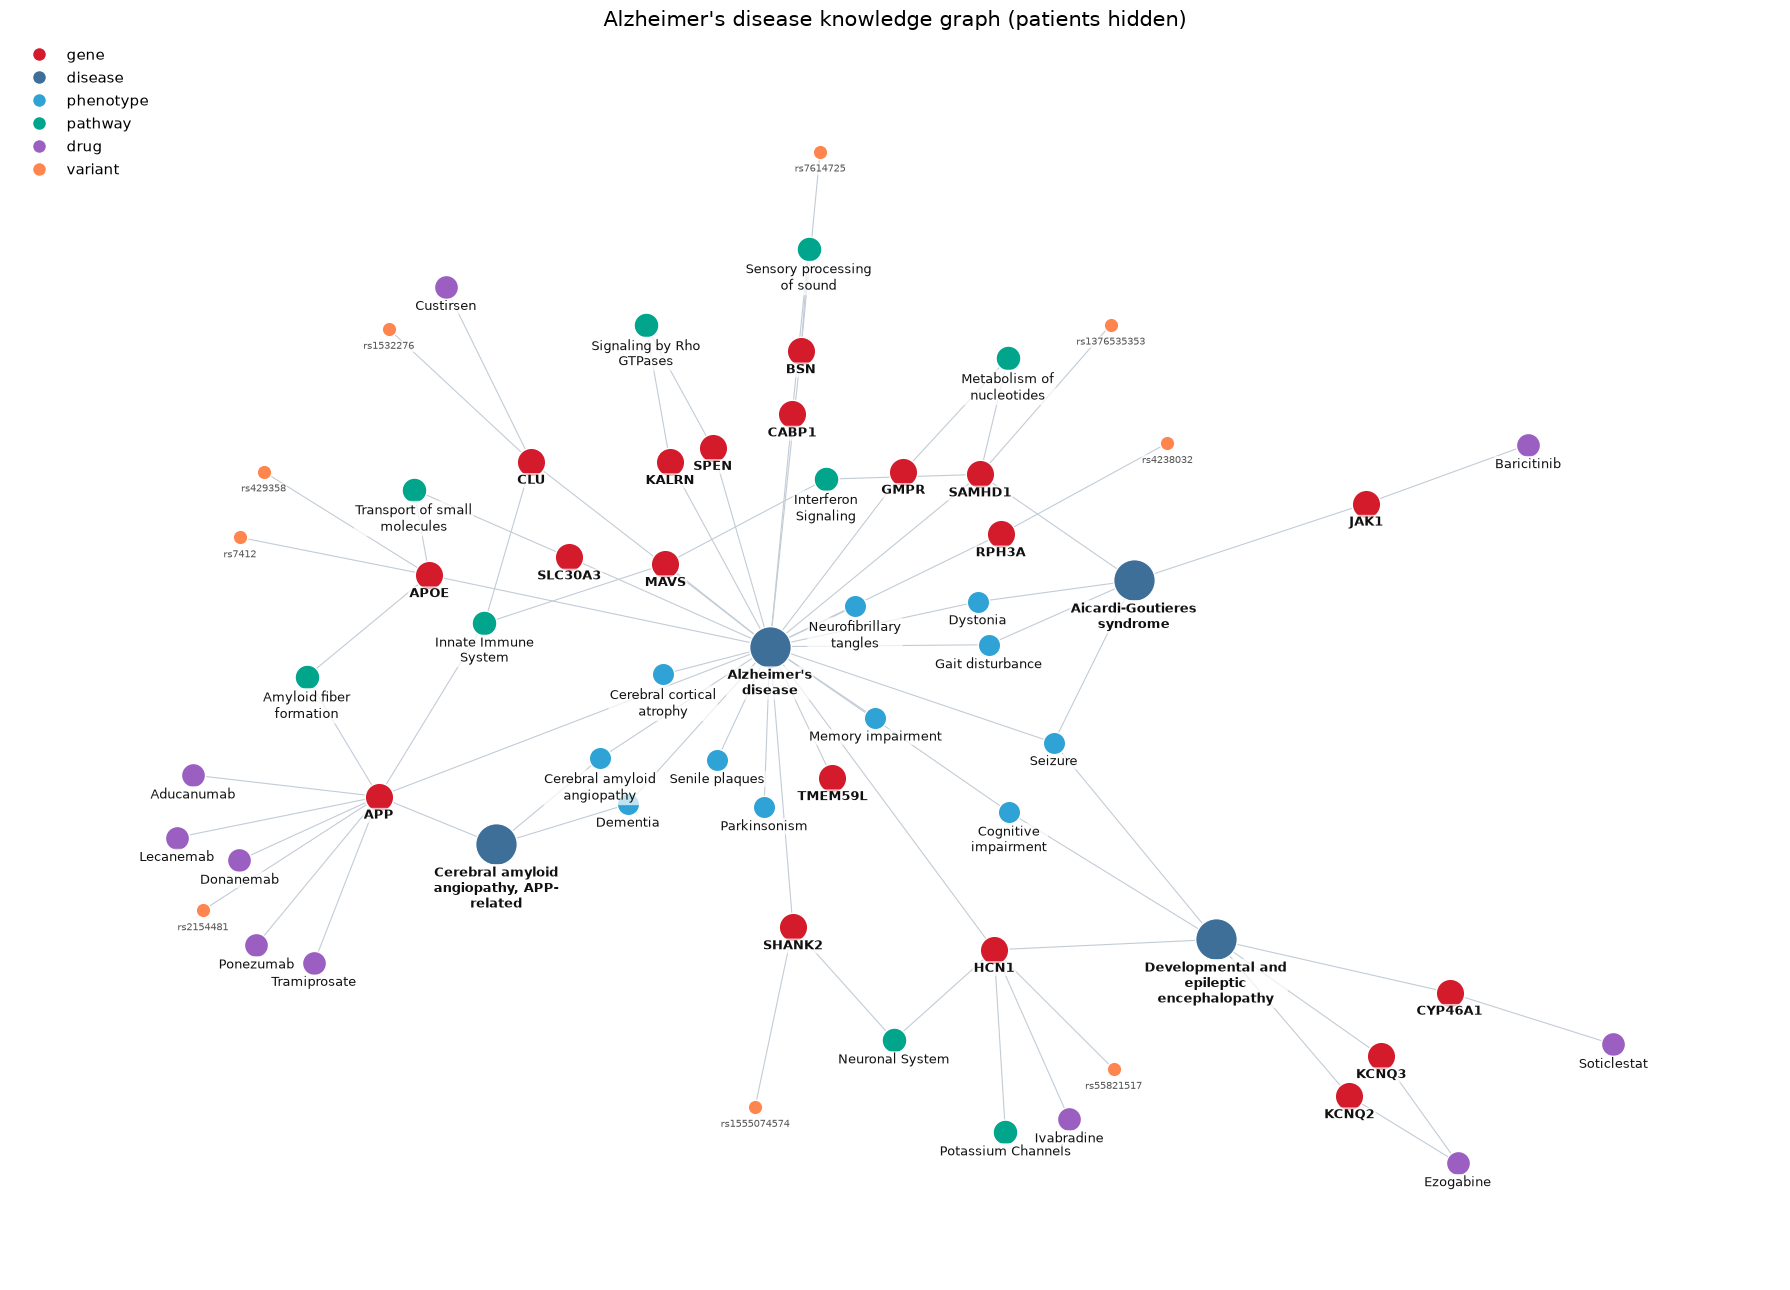

saved images/my_knowledge_graph.png, images/nodes.csv, images/edges.csv


In [9]:
import matplotlib.pyplot as plt
import textwrap
from matplotlib.lines import Line2D

KIND_COLOR = {"gene":"#D41B2C","disease":"#3E6F99","phenotype":"#2FA3D6",
              "pathway":"#00A58C","drug":"#9A5FC0","variant":"#FF854F","patient":"#8A94A3"}
# CHANGED from the starter for legibility: node size by kind (diseases largest, variants smallest)
KIND_SIZE  = {"disease":900, "gene":420, "pathway":320, "drug":300, "phenotype":260, "variant":110}

H = G.subgraph([n for n, d in G.nodes(data=True) if d["kind"] != "patient"])
U = H.to_undirected()
# CHANGED: Kamada-Kawai gives an even global spread; a long spring pass from that start
# then pushes apart nodes that still overlap (the starter used one short spring pass).
pos = nx.kamada_kawai_layout(U)
pos = nx.spring_layout(U, pos=pos, seed=7, k=3.0 / len(U) ** 0.5, iterations=300)

fig, ax = plt.subplots(figsize=(18, 13))
nx.draw_networkx_edges(U, pos, ax=ax, edge_color="#C2CCD6", width=0.8)
for kind, color in KIND_COLOR.items():
    nl = [n for n in H if H.nodes[n]["kind"] == kind]
    nx.draw_networkx_nodes(U, pos, nodelist=nl, ax=ax, node_color=color,
                           node_size=KIND_SIZE.get(kind, 300), edgecolors="white", linewidths=1)
# CHANGED: labels sit just below each node (not on top of it), long names wrap,
# genes/diseases are bold, and a light white backing keeps text readable over edges.
for n, (x, y) in pos.items():
    k = H.nodes[n]["kind"]
    ax.annotate(textwrap.fill(n, 18), (x, y), xytext=(0, -15 if k == "disease" else -9),
                textcoords="offset points", ha="center", va="top", zorder=5,
                fontsize=7 if k == "variant" else 9,
                fontweight="bold" if k in ("gene", "disease") else "normal",
                color="#555" if k == "variant" else "#111",
                bbox=dict(boxstyle="round,pad=0.1", fc="white", ec="none", alpha=0.7))
# CHANGED: colour legend so the node types can be read without the code
ax.legend(handles=[Line2D([0], [0], marker="o", ls="", ms=10, mfc=c, mec="white", label=k)
                   for k, c in KIND_COLOR.items() if k != "patient"],
          loc="upper left", frameon=False, fontsize=11)
ax.margins(0.06); ax.axis("off")
ax.set_title(f"{DISEASE} knowledge graph (patients hidden)", fontsize=15)
fig.tight_layout()
os.makedirs("images", exist_ok=True)   # all Module 7 outputs go in images/
plt.savefig("images/my_knowledge_graph.png", dpi=150, bbox_inches="tight")   # <- commit this
plt.show()

# export node and edge tables (commit the CSVs)
pd.DataFrame([dict(name=n, **d) for n, d in NODES.items()]).to_csv("images/nodes.csv", index=False)
pd.DataFrame(EDGES).to_csv("images/edges.csv", index=False)
print("saved images/my_knowledge_graph.png, images/nodes.csv, images/edges.csv")

## 8 · Your report (the 40%)

Write a **3–4 page report** answering these four, in your own words:

1. **Schema and evidence** — why these node and edge types, and what evidence you put on the edges.
2. **Top targets** — which genes rank highest by centrality (§5), and does that match the biology you expect? Any non-obvious hit?
3. **A hypothesis from a path** — one repurposing or shared-mechanism hypothesis a path in your graph suggests (§4), and what would test it.
4. **Limitations** — an edge is evidence, not truth. Which of your edges are weak, and how would the answer change with better data? Note where you used (or would use) AI to harmonize data or write queries, and how you checked it.

#### Submit
- This notebook (**Kernel → Restart & Run All** first; credentials in a git-ignored file, not committed).
- `my_knowledge_graph.png`, `nodes.csv`, `edges.csv`.
- Your 3–4 page report (PDF) and a short README (name + your disease).
- Push to your biot6900 repo and post the link on Canvas.

#### Reset (to start over)
```cypher
MATCH (n) DETACH DELETE n      // wipes the database — run deliberately
```
